> **Validation status (2026-10-02):** This notebook is a corrected exploratory view of the broad T7 snapshot. Its figures and code use the stable ticker-prefix universe, within-bucket mean probabilities, and final-recorded-trade VWAP anchors, but the current Trump conclusion is the executed [consolidated validation notebook](output/mention-markets-validation-consolidated.ipynb) and [issue report](output/mention-markets-validation-report.md).

# Calibration Errors and Trading Opportunities in Kalshi Political Speech Mention Markets

**Abstract.** This notebook examines persistent calibration errors in political speech mention markets on Kalshi, a CFTC-regulated prediction exchange. The dataset covers ~18,000+ resolved binary contracts across political speech mention series, which we divide into four subgroups for analysis:

1. **Trump Markets** -- the highest-volume series, centered on mentions during Trump speeches and rallies.
2. **Press Briefings** -- White House Secretary of the Press daily briefing mention contracts.
3. **Mamdani / NYC Mayoral** -- mention markets around Zohran Mamdani and the NYC mayoral race.
4. **Niche / One-offs** -- lower-volume political mention markets (Biden, Vance, Walz, AOC, etc.).

We measure calibration at multiple VWAP horizons, quantify directional accuracy, and backtest simple threshold strategies that exploit the observed longshot bias -- all net of Kalshi's taker fee schedule.

---
## 0. Setup

In [1]:
import sys
sys.path.insert(0, ".")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

from src.data_loading import load_mention_markets, load_trade_positions, VWAP_INTERVALS
from src.mention_filters import (
    get_category, assign_political_subgroup, POLITICAL_SERIES
)
from src.metrics import (
    kalshi_fee, calibration_buckets, compute_mad, multi_horizon_calibration,
    strategy_profits, extremes_strategy, calibration_deviation_over_time
)
from src.plotting import (
    apply_style, plot_calibration_curve, plot_multi_horizon_calibration,
    plot_calibration_panel, plot_mad_summary, plot_vwap_traces,
    plot_calibration_deviation_over_time, plot_strategy_comparison,
    plot_profit_heatmap, C_BLUE, C_GREEN, C_RED, C_GRAY, C_LIGHTBLUE
)

apply_style()

---
## 1. Load Data

We start by loading **all** resolved mention markets from the parquet data on the T7 SSD (symlinked under `data/`), then filter down to the **Politicians** category. Each contract is assigned to one of four political subgroups. The 2-hour VWAP serves as our primary implied-probability snapshot.

**VWAP definition:** each `vwap_h` is a cumulative pre-cutoff VWAP using all trades at or before `last_trade_time − h`; it is not a trailing-window VWAP over the preceding `h` hours.


In [2]:
print("Loading mention market data...")
df_all = load_mention_markets()
print(f"Loaded {len(df_all)} total mention contracts")

# Categorize by the stable ticker prefix.  Some Trump rows have metadata
# series values "A" or "B", so categorizing on series alone drops them.
df_all["category"] = df_all["ticker"].apply(get_category)
df_mention = df_all[df_all["category"] == "Politicians"].copy()
df_mention["subgroup"] = df_mention["ticker"].apply(assign_political_subgroup)
df_mention["actual_yes"] = df_mention["result"] == "yes"
df_mention = df_mention.dropna(subset=["vwap_2h"]).copy()

# Directional accuracy
df_mention["predicted_yes"] = df_mention["vwap_2h"] > 50.0
df_mention["correct"] = df_mention["predicted_yes"] == df_mention["actual_yes"]

print(f"Political mention contracts: {len(df_mention)}")
print("Subgroup distribution:")
print(df_mention["subgroup"].value_counts().to_string())


Loading mention market data...


Loaded 21975 total mention contracts


Political mention contracts: 10271
Subgroup distribution:
subgroup
Group 1: Trump Markets               6352
Group 4: Niche / One-offs            2163
Group 2: Press Briefings             1032
Group 3: Mayoral (Zohran Mamdani)     724


---
## 2. Calibration Deviation Over Time

This is a **descriptive, cumulative snapshot series**, not a sequence of independent market forecasts. At each weekly date we aggregate both taker and counterparty trade positions observed so far, then compute the mean absolute deviation between their entry prices and realized outcomes. Because positions from the same contract and event are repeated, the chart is trade-position-weighted and should not be interpreted as causal evidence that calibration improves near an event.

The analysis uses `last_trade_time` as the VWAP anchor. The raw `close_time` is a settlement/payout timestamp and is not the same event-time reference.

We require a minimum of 500 cumulative trade positions before the first point to reduce noisy early estimates.


Loading trade positions for calibration over time analysis...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 9277598 trade positions


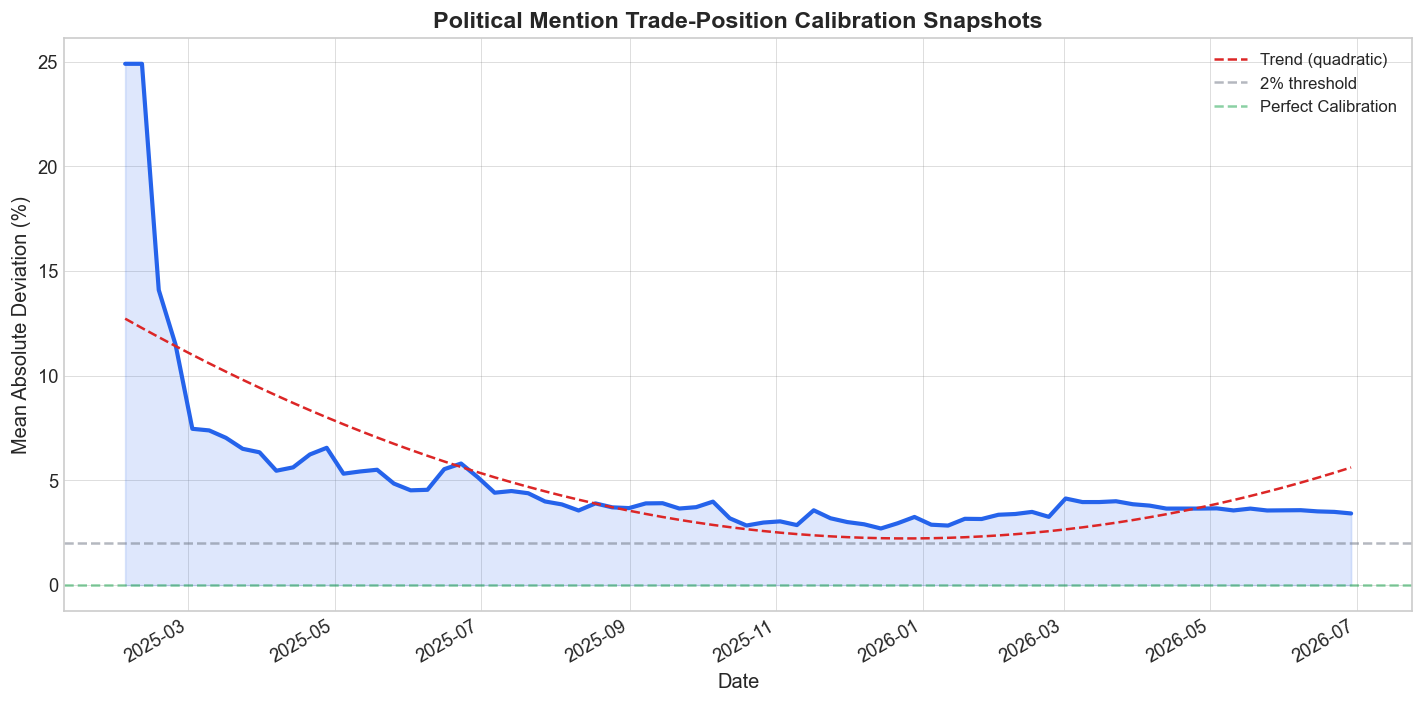

In [3]:
# Load trade positions for the descriptive cumulative snapshots
print("Loading trade positions for calibration over time analysis...")
df_positions = load_trade_positions()
df_positions["category"] = df_positions["ticker"].apply(get_category)
df_positions = df_positions[df_positions["category"] == "Politicians"].copy()
print(f"Loaded {len(df_positions)} trade positions")

df_cal = calibration_deviation_over_time(df_positions, min_cumulative=500)

fig = plot_calibration_deviation_over_time(
    df_cal,
    title="Political Mention Trade-Position Calibration Snapshots",
    show_trend=True,
)
plt.show()


In [4]:
print("=== Political Mention Cumulative Trade-Position Snapshots ===")
print(f"Mean absolute deviation across weekly snapshots: {df_cal['mean_absolute_deviation'].mean():.2f} percentage points")
print(f"Early period (first 8 weeks):                   {df_cal['mean_absolute_deviation'].head(8).mean():.2f} percentage points")
print(f"Recent period (last 8 weeks):                  {df_cal['mean_absolute_deviation'].tail(8).mean():.2f} percentage points")
slope = np.polyfit(range(len(df_cal)), df_cal["mean_absolute_deviation"], 1)[0]
print(f"\nDescriptive slope: {slope:.3f} percentage points/week ({'declining' if slope < 0 else 'increasing'})")
print("Interpret the slope as change in this cumulative trade-position snapshot, not as an independent contract-level time series.")


=== Political Mention Cumulative Trade-Position Snapshots ===
Mean absolute deviation across weekly snapshots: 4.93 percentage points
Early period (first 8 weeks):                   12.97 percentage points
Recent period (last 8 weeks):                  3.55 percentage points

Descriptive slope: -0.097 percentage points/week (declining)
Interpret the slope as change in this cumulative trade-position snapshot, not as an independent contract-level time series.


---
## 3. Overall Calibration Curve

A calibration curve plots the **actual YES resolution rate** against the **mean observed market-implied probability** (here, the 2-hour VWAP). A perfectly calibrated market lies on the 45-degree diagonal. Each bucket is plotted at its within-bucket mean price; using a fixed bucket midpoint would be only an approximation when prices cluster near one edge.

The shaded regions highlight the high (70%+) and low (under 30%) probability ranges used in the Trump audit. They are descriptive regions, not proof of a trading opportunity.


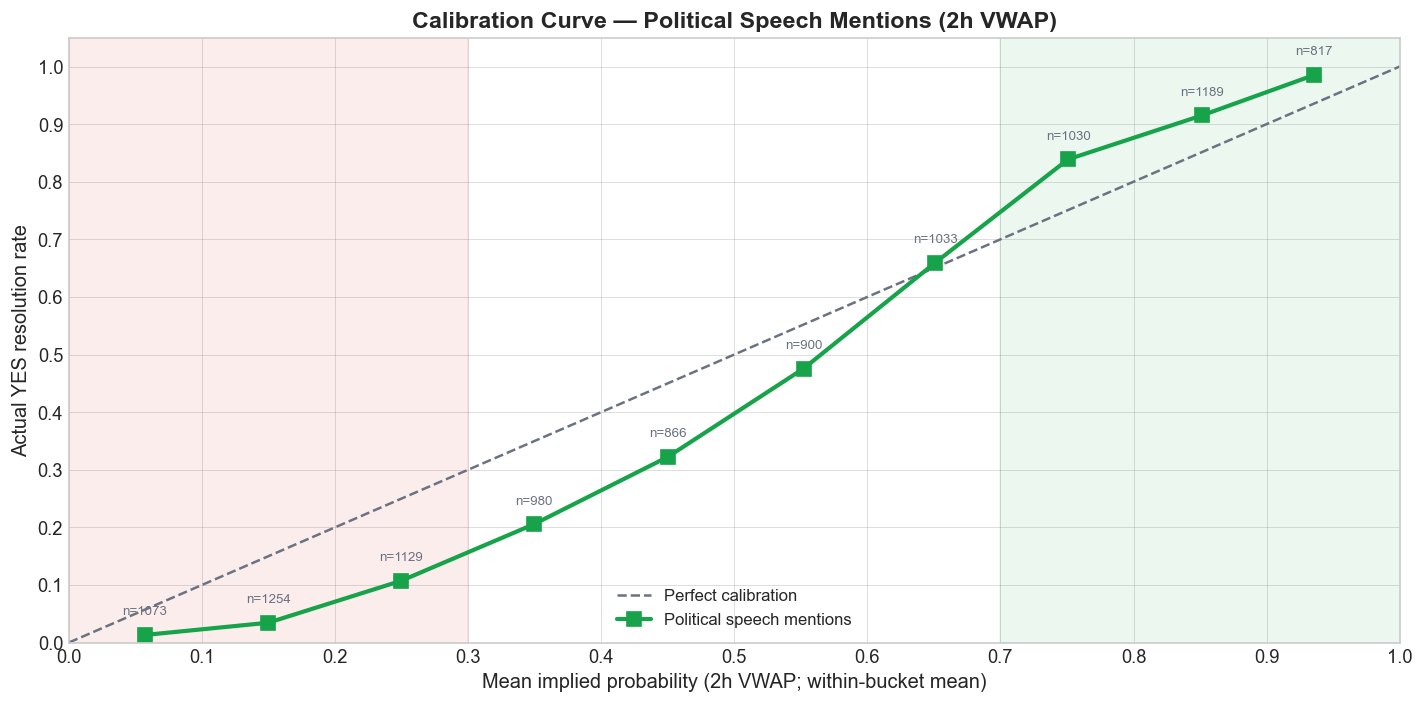

In [5]:
# Overall political mention calibration using 2h VWAP
cal_pol = calibration_buckets(df_mention, "vwap_2h", bin_size=10)

fig, ax = plt.subplots(figsize=(12, 6))
ax = plot_calibration_curve(cal_pol, ax=ax, label="Political speech mentions", color=C_GREEN, marker="s")
ax.set_xlabel("Mean implied probability (2h VWAP; within-bucket mean)", fontsize=12)
ax.set_ylabel("Actual YES resolution rate", fontsize=12)
ax.set_title("Calibration Curve — Political Speech Mentions (2h VWAP)", fontsize=14, fontweight="bold")

ax.axvspan(0.70, 1.0, alpha=0.08, color=C_GREEN, zorder=1)
ax.axvspan(0.0, 0.30, alpha=0.08, color=C_RED, zorder=1)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()


---
## 4. Directional Accuracy by Subgroup

**Directional accuracy** measures the simplest possible prediction: does the 2-hour VWAP correctly predict the market outcome? If the VWAP exceeds 50 cents we predict YES; otherwise NO. A market with any predictive content should exceed 50%, and a well-calibrated market should score well above that.

We compute directional accuracy for each of the four political subgroups and overlay the contract count to contextualize statistical reliability.

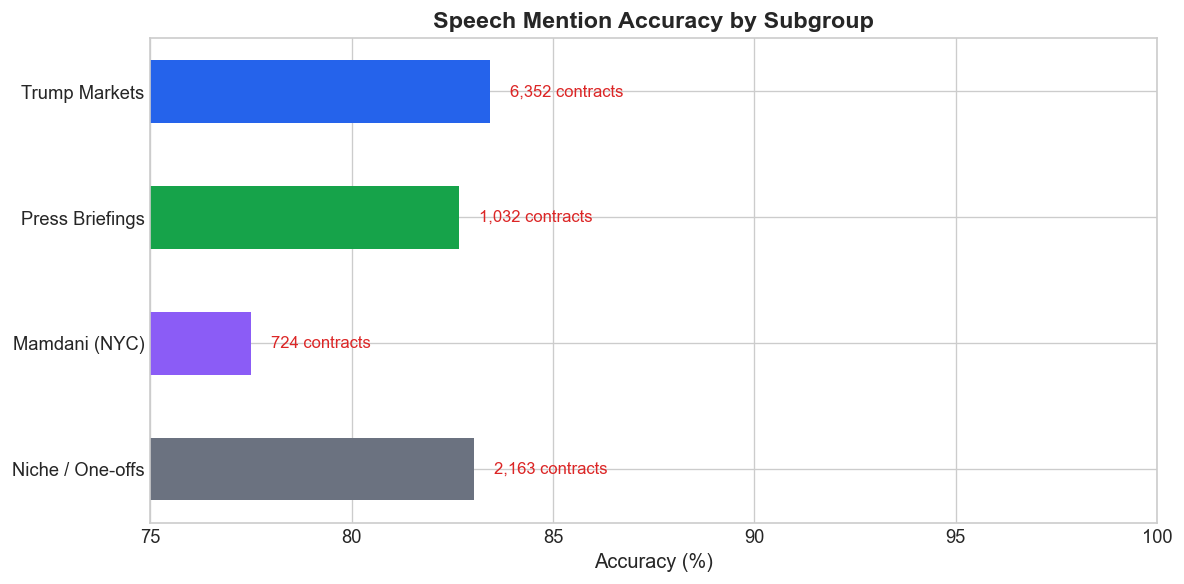

In [6]:
subgroups = ["Group 1: Trump Markets", "Group 2: Press Briefings",
             "Group 3: Mayoral (Zohran Mamdani)", "Group 4: Niche / One-offs"]

df_sub = []
for g in subgroups:
    g_df = df_mention[df_mention["subgroup"] == g]
    acc = g_df["correct"].mean()
    tot = len(g_df)
    
    # Strategy profits
    strat = strategy_profits(g_df, thresholds=[60, 70, 80, 90])
    ext = extremes_strategy(g_df)
    
    row = {
        "subgroup": g,
        "total_mention_contracts": tot,
        "accuracy": acc,
        "ext_trades": ext["trades"],
        "ext_profit": ext["net_return"],
    }
    for _, s in strat.iterrows():
        t = int(s["threshold"])
        row[f"gt{t}_trades"] = int(s["trades"])
        row[f"gt{t}_profit"] = s["net_return"]
    df_sub.append(row)

df_sub = pd.DataFrame(df_sub)

# Accuracy bar chart
fig, ax = plt.subplots(figsize=(10, 5))
colors = [C_BLUE, C_GREEN, "#8b5cf6", C_GRAY]
short_labels = ["Trump Markets", "Press Briefings", "Mamdani (NYC)", "Niche / One-offs"]
bars = ax.barh(short_labels[::-1], df_sub["accuracy"].values[::-1] * 100, color=colors[::-1], height=0.5)
for bar, n in zip(bars, df_sub["total_mention_contracts"].values[::-1]):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{n:,} contracts", va="center", fontsize=10, color=C_RED)
ax.set_xlabel("Accuracy (%)", fontsize=12)
ax.set_title("Speech Mention Accuracy by Subgroup", fontsize=14, fontweight="bold")
ax.set_xlim(75, 100)
plt.tight_layout()
plt.show()

---
## 5. Subgroup Calibration Deep Dives

Each subgroup has distinct market dynamics. Below we produce faceted calibration charts for every subgroup, showing how the calibration curve behaves across three bucket granularities (1-cent, 5-cent, and 10-cent) and six VWAP horizons (1 day, 6 hours, 2 hours, 1 hour, 30 minutes, 10 minutes).

### 5.1 Group 1: Trump Markets

The Trump mention series (`KXTRUMPMENTION`) is by far the most liquid and highest-volume political mention market. These contracts resolve based on whether specific words or phrases are mentioned during Trump rallies, press conferences, and other public appearances. The high volume provides the most statistically robust calibration estimates.

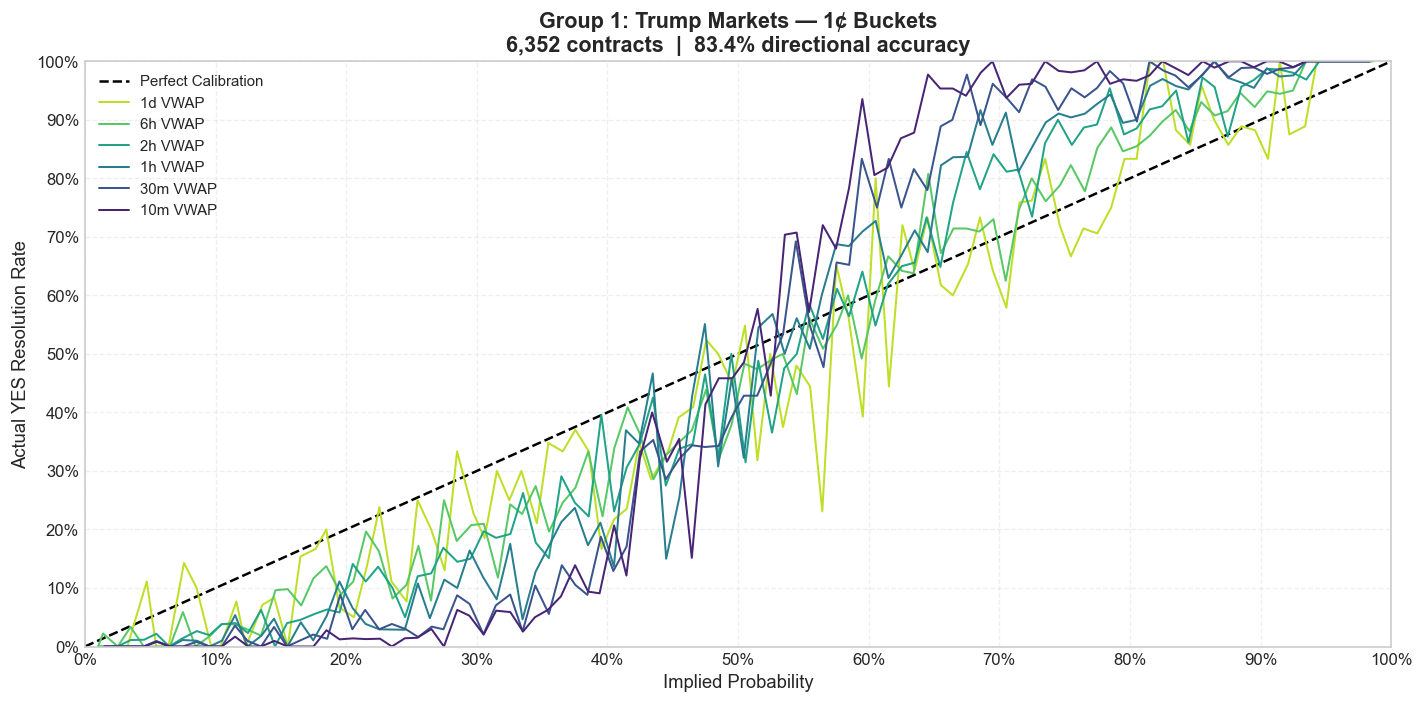

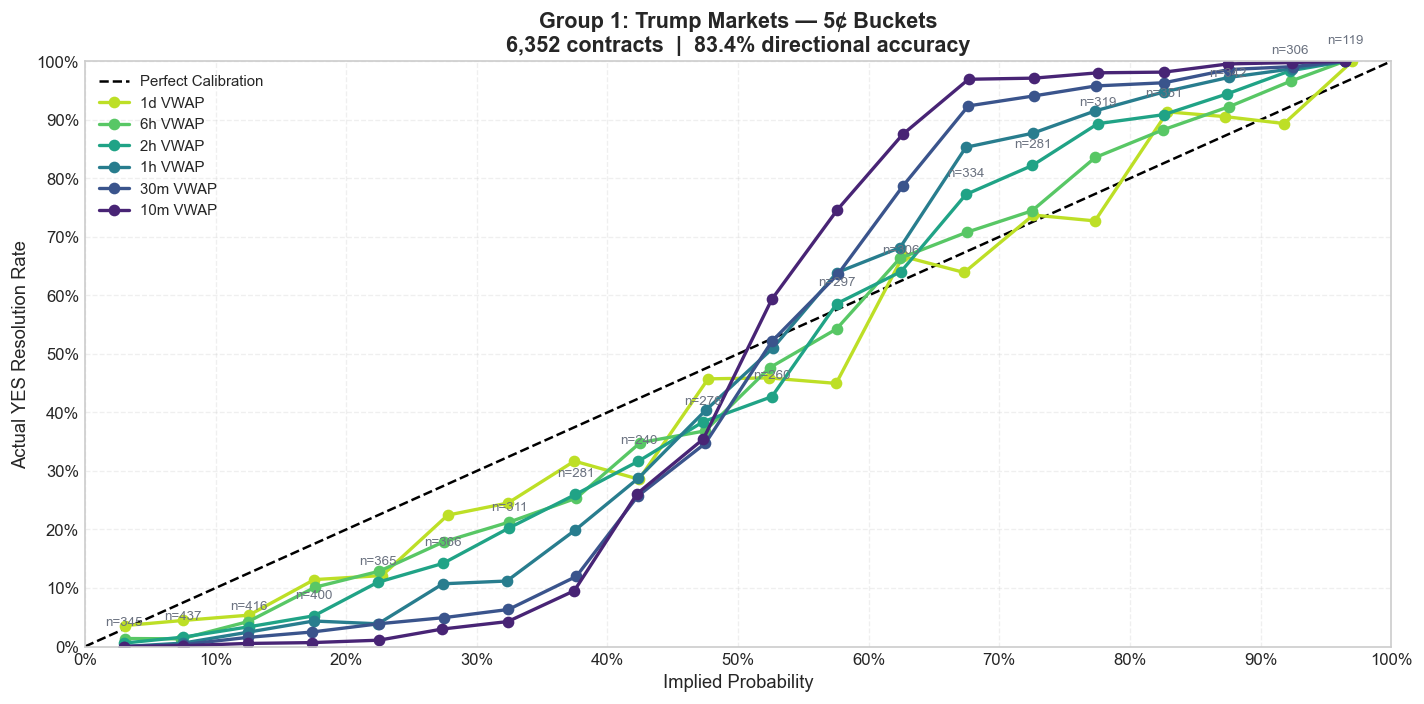

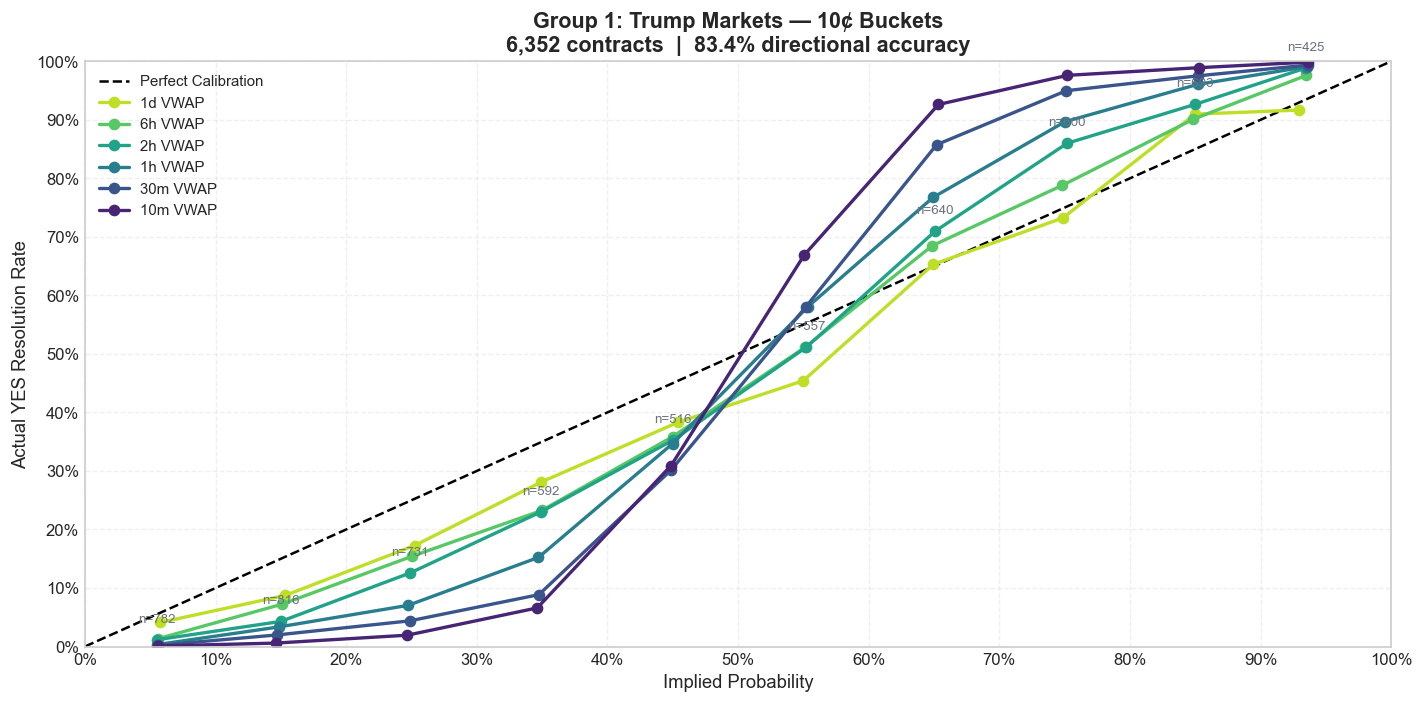

In [7]:
# Group 1: Trump Markets — individual charts per bucket granularity
intervals = ["1d", "6h", "2h", "1h", "30m", "10m"]
trump_row = df_sub[df_sub["subgroup"] == "Group 1: Trump Markets"].iloc[0]
trump_df = df_mention[df_mention["subgroup"] == "Group 1: Trump Markets"].copy()

for bs in [1, 5, 10]:
    fig = plot_calibration_panel(trump_df, "Group 1: Trump Markets",
        int(trump_row["total_mention_contracts"]), trump_row["accuracy"],
        intervals, bin_size=bs)
    plt.show()

### 5.2 Group 2: Press Briefings

White House Secretary of the Press briefing mention contracts (`KXSECPRESSMENTION`) cover daily briefings. These are notable for their regularity -- briefings happen on a predictable schedule -- and the relatively constrained vocabulary. This subgroup tests whether routine, recurring events are priced more efficiently than ad-hoc speeches.

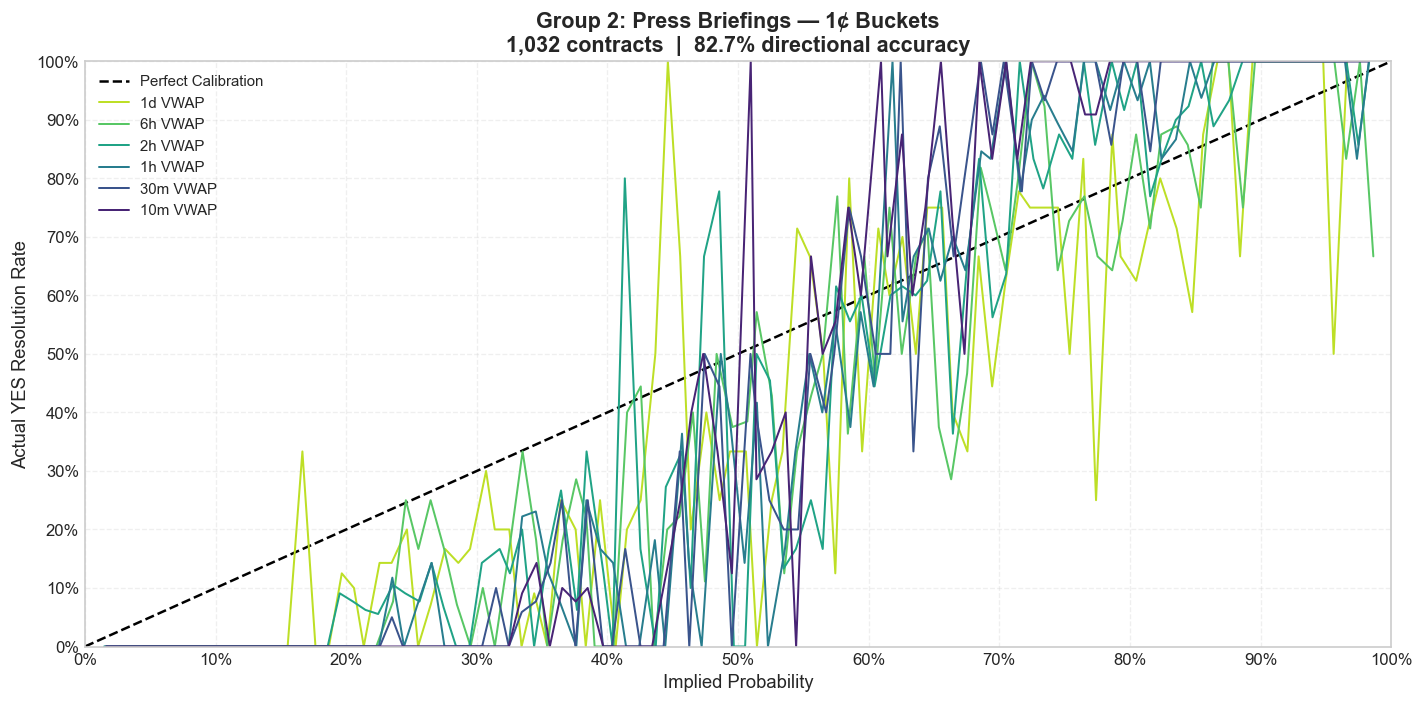

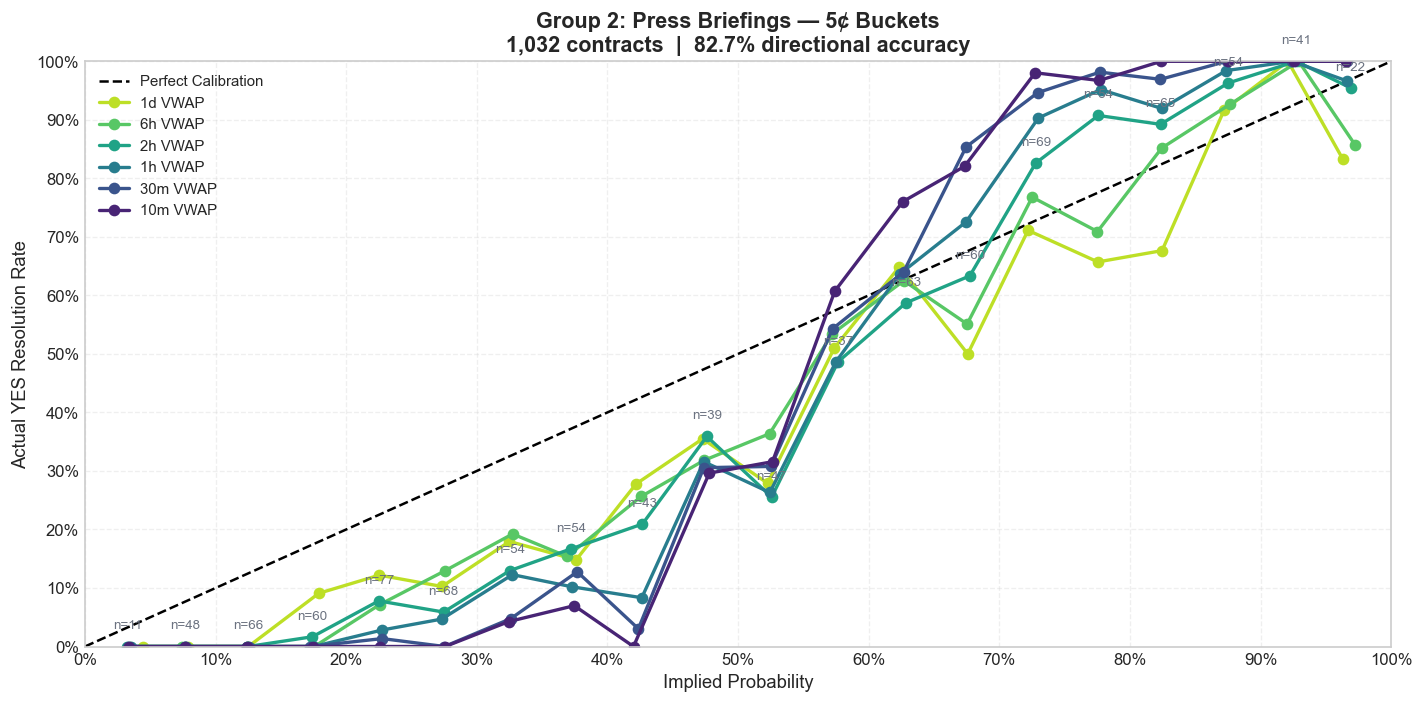

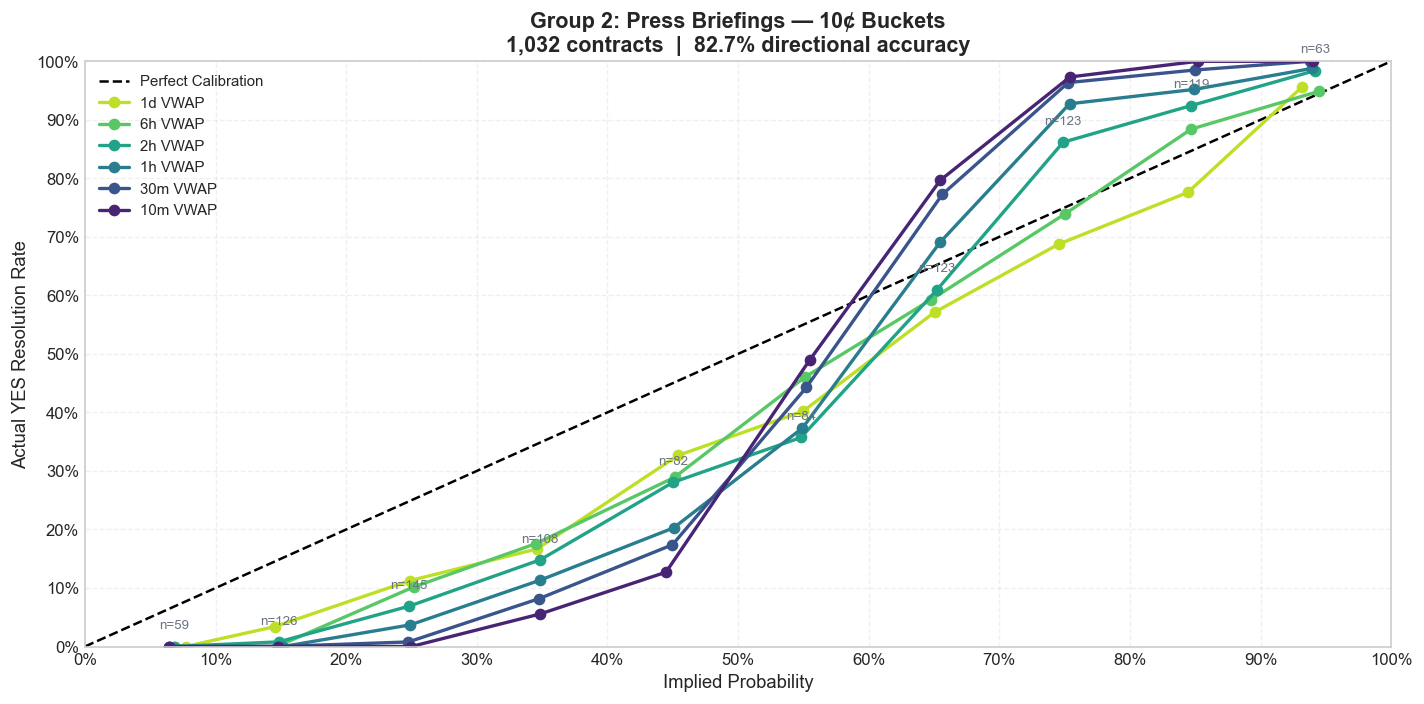

In [8]:
# Group 2: Press Briefings — individual charts per bucket granularity
press_row = df_sub[df_sub["subgroup"] == "Group 2: Press Briefings"].iloc[0]
press_df = df_mention[df_mention["subgroup"] == "Group 2: Press Briefings"].copy()

for bs in [1, 5, 10]:
    fig = plot_calibration_panel(press_df, "Group 2: Press Briefings",
        int(press_row["total_mention_contracts"]), press_row["accuracy"],
        intervals, bin_size=bs)
    plt.show()

### 5.3 Group 3: Mamdani / NYC Mayoral

The Zohran Mamdani and NYC mayoral debate mention series (`KXMAMDANIMENTION`, `KXNYCMAYORDEBATEMENTION`) represent a niche but active political mention market. Given the lower national profile compared to Trump or White House briefings, we might expect thinner liquidity and potentially larger calibration errors.

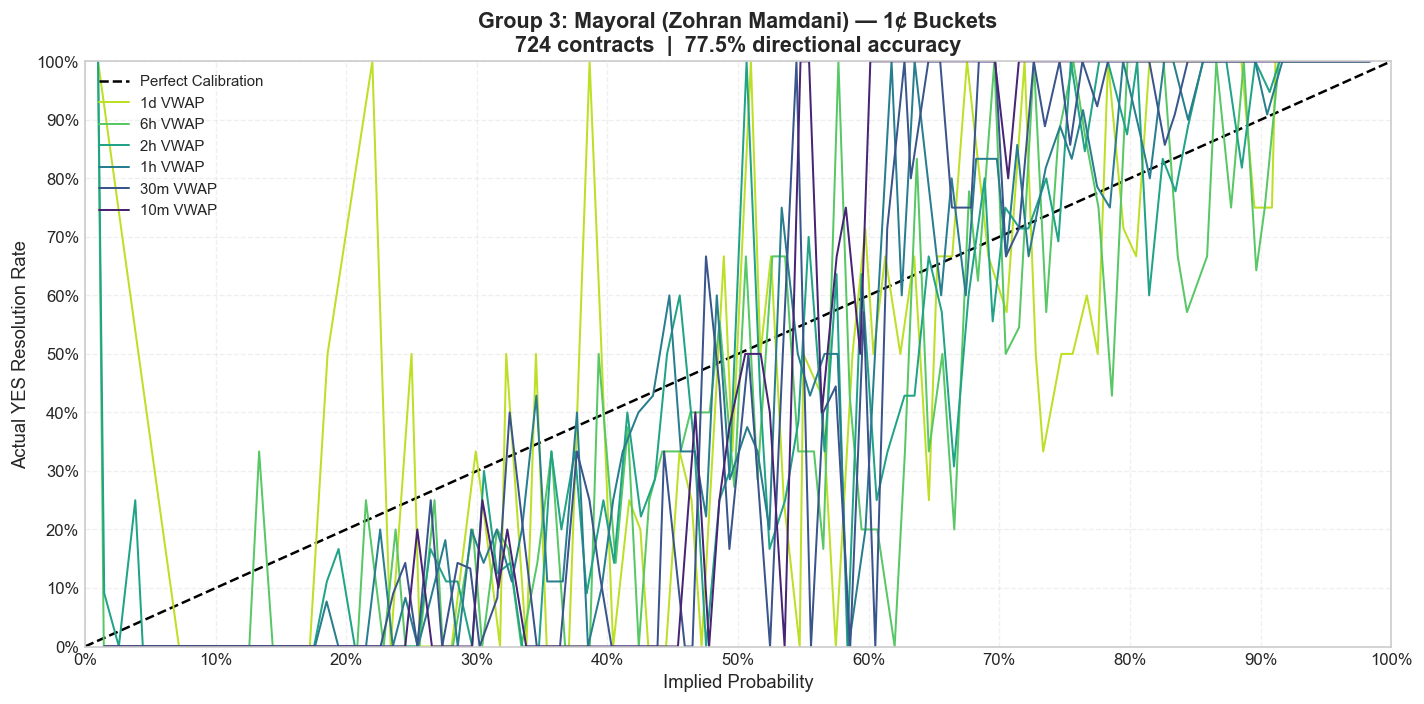

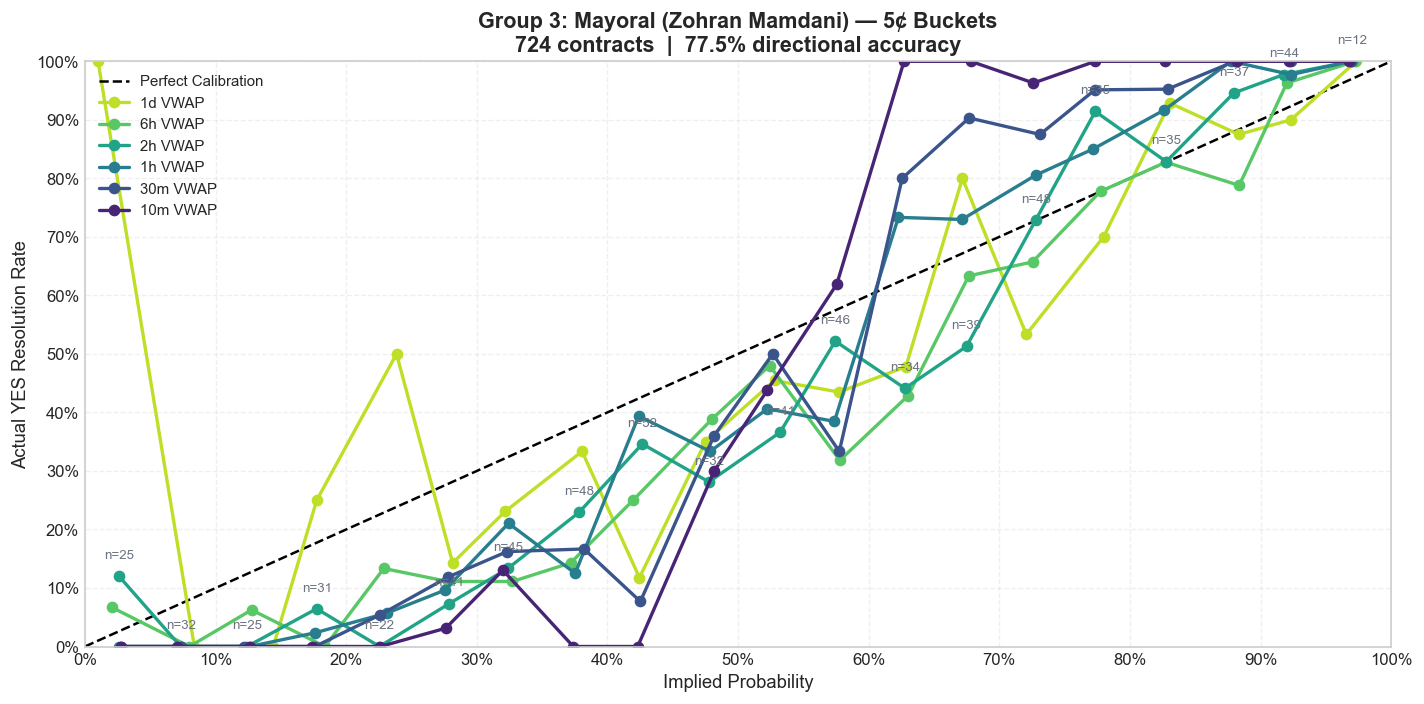

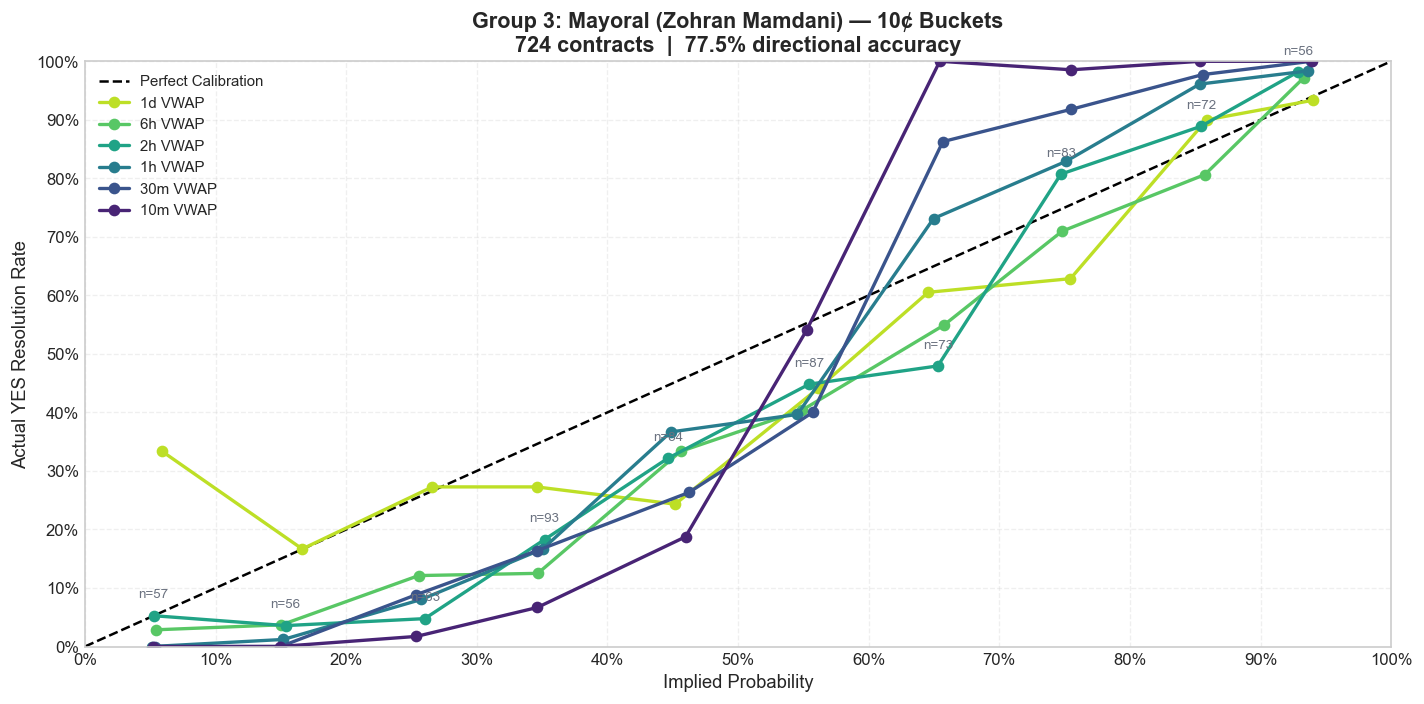

In [9]:
# Group 3: Mayoral (Zohran Mamdani) — individual charts per bucket granularity
mamdani_row = df_sub[df_sub["subgroup"] == "Group 3: Mayoral (Zohran Mamdani)"].iloc[0]
mamdani_df = df_mention[df_mention["subgroup"] == "Group 3: Mayoral (Zohran Mamdani)"].copy()

for bs in [1, 5, 10]:
    fig = plot_calibration_panel(mamdani_df, "Group 3: Mayoral (Zohran Mamdani)",
        int(mamdani_row["total_mention_contracts"]), mamdani_row["accuracy"],
        intervals, bin_size=bs)
    plt.show()

### 5.4 Group 4: Niche / One-offs

This residual category includes all other political mention series: Biden, Vance, Bernie Sanders, AOC, Hegseth, Hochul, DeSantis, and many more. Each individual series may have limited sample size, but in aggregate they reveal whether the calibration patterns observed in the high-volume series generalize to the long tail of political mention markets.

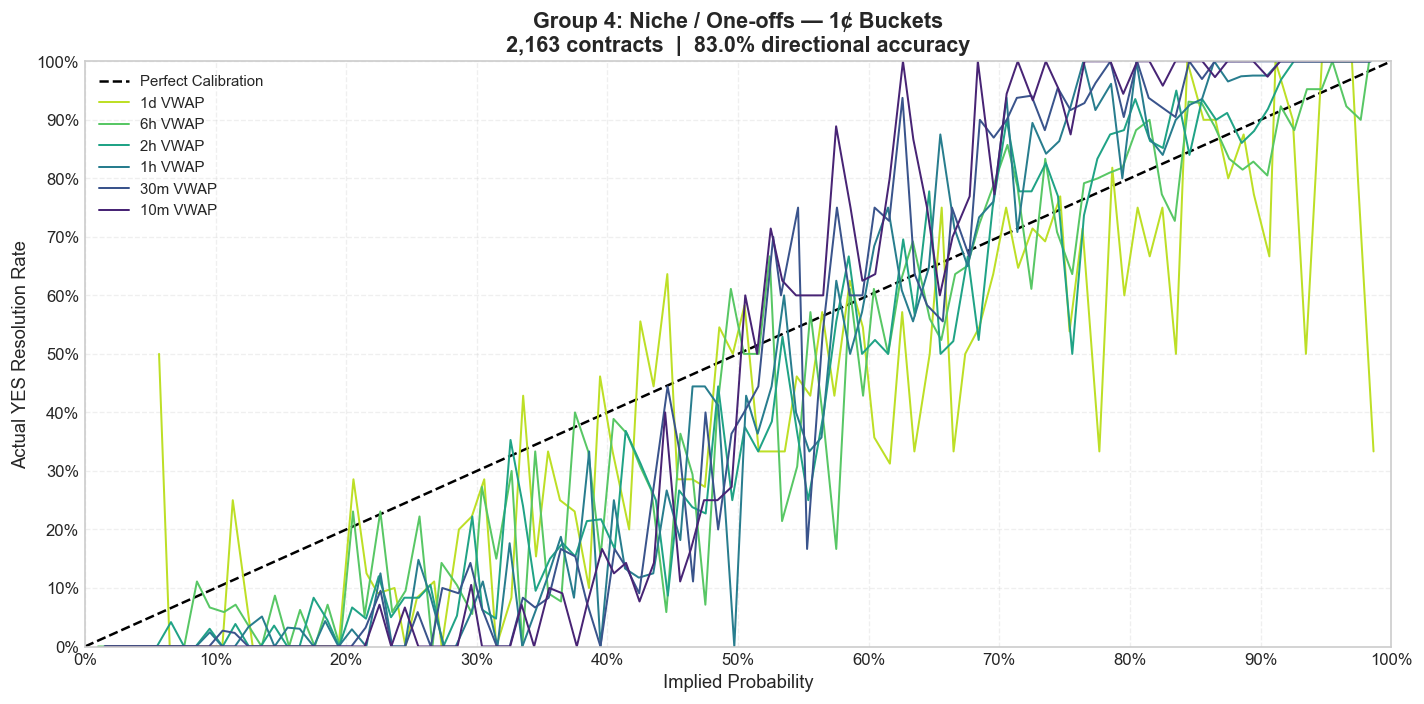

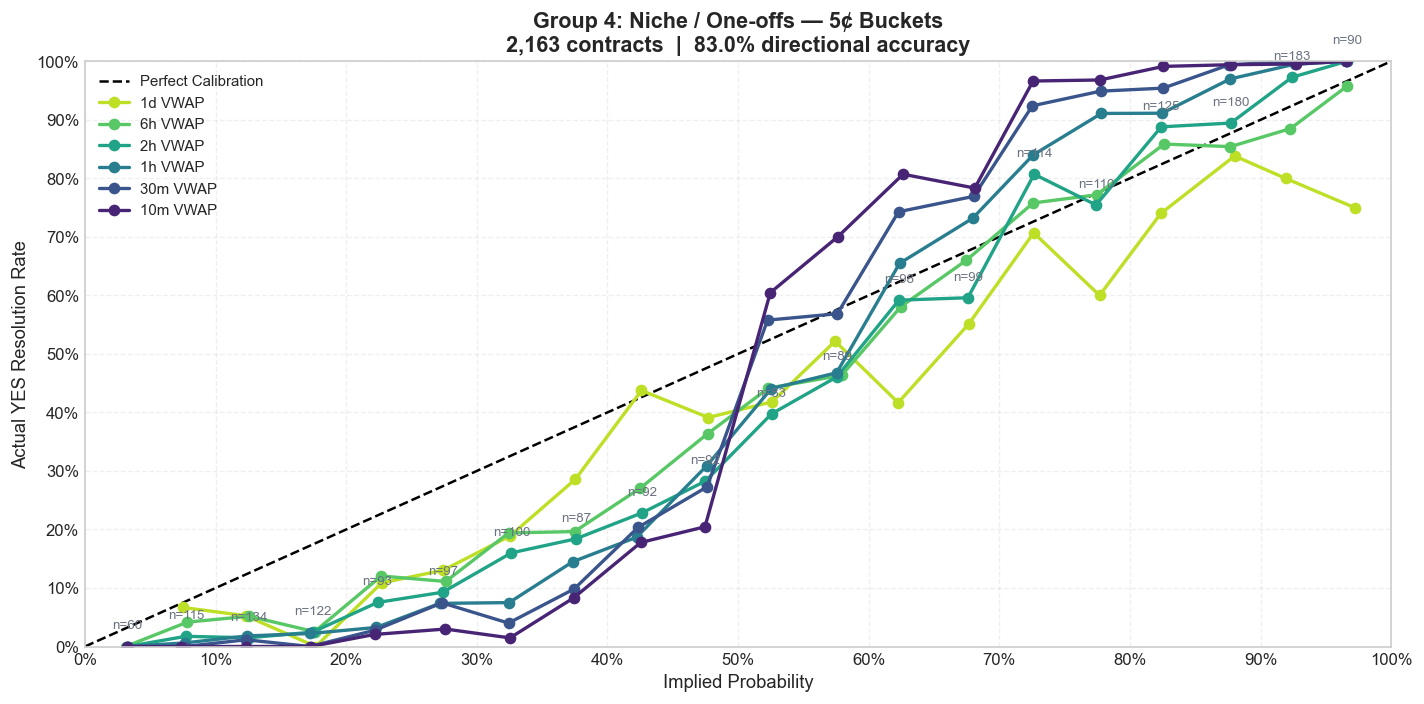

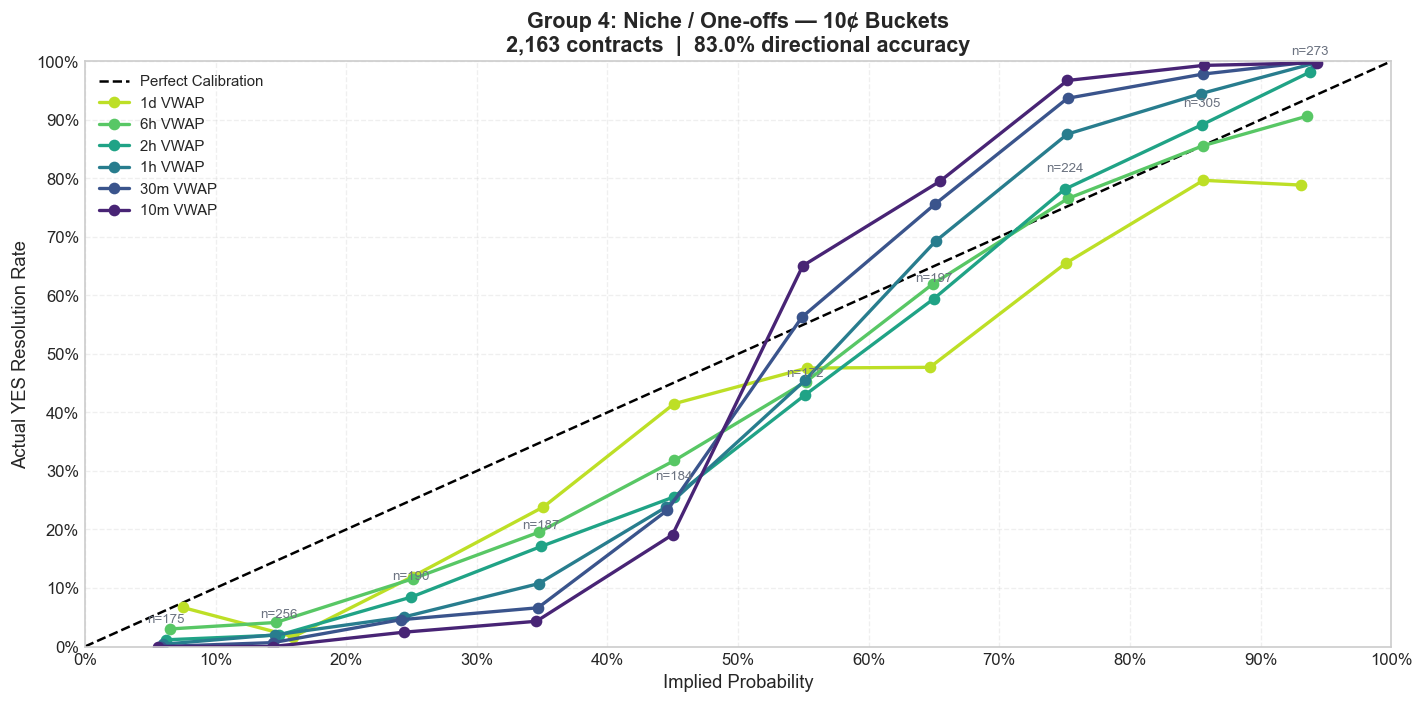

In [10]:
# Group 4: Niche / One-offs — individual charts per bucket granularity
niche_row = df_sub[df_sub["subgroup"] == "Group 4: Niche / One-offs"].iloc[0]
niche_df = df_mention[df_mention["subgroup"] == "Group 4: Niche / One-offs"].copy()

for bs in [1, 5, 10]:
    fig = plot_calibration_panel(niche_df, "Group 4: Niche / One-offs",
        int(niche_row["total_mention_contracts"]), niche_row["accuracy"],
        intervals, bin_size=bs)
    plt.show()

---
## 6. VWAP Traces

These spaghetti plots are a diagnostic view of per-contract VWAP paths indexed by time before each market's final recorded trade. They show outcome separation and path heterogeneity, but they are not event-aligned trajectories: different contracts have different speech schedules and missing long-horizon observations. Use the calibration tables for numeric comparisons.


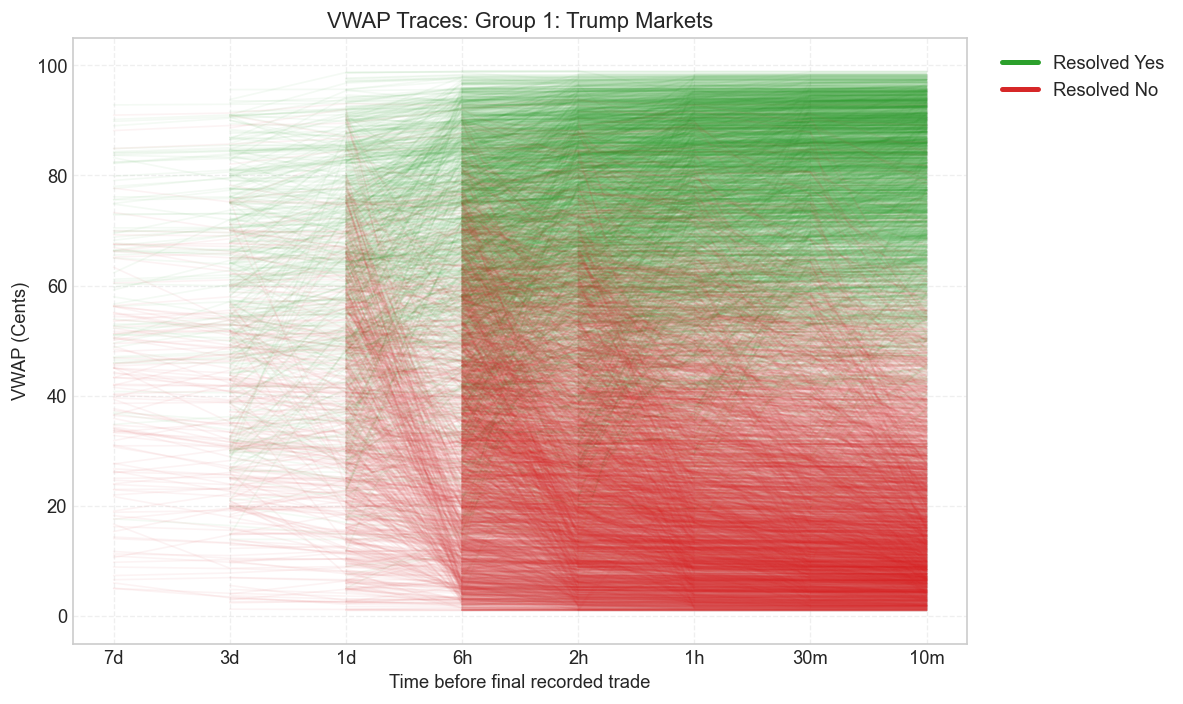

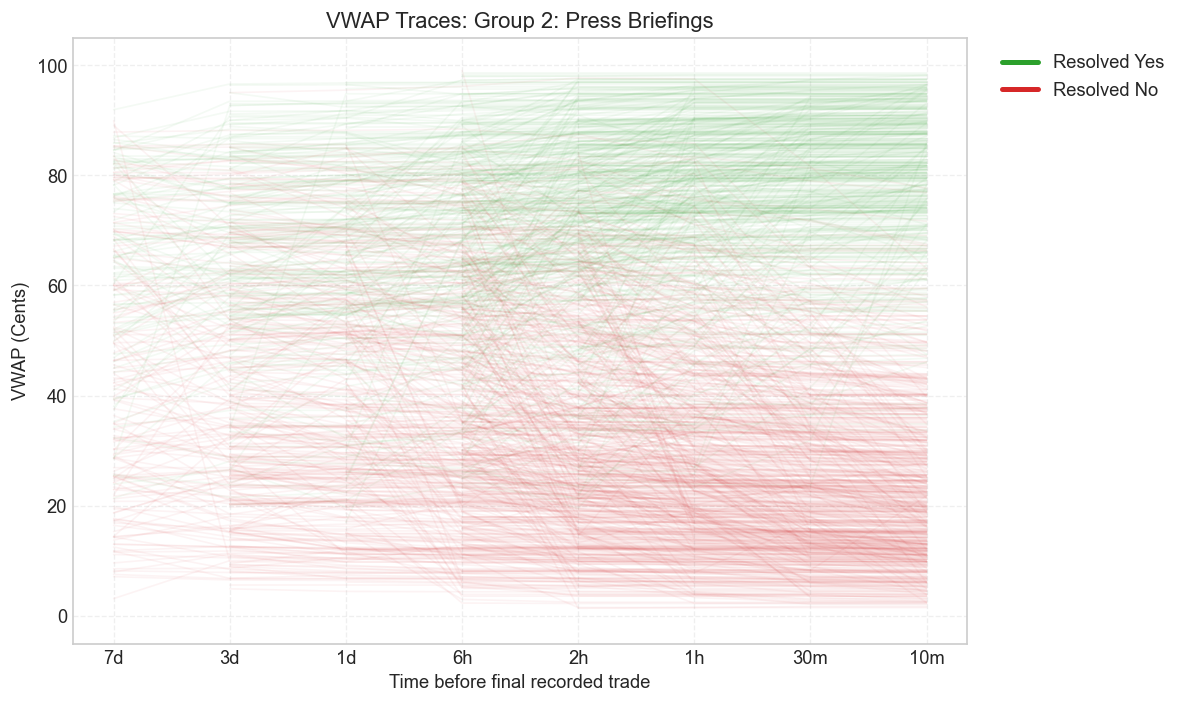

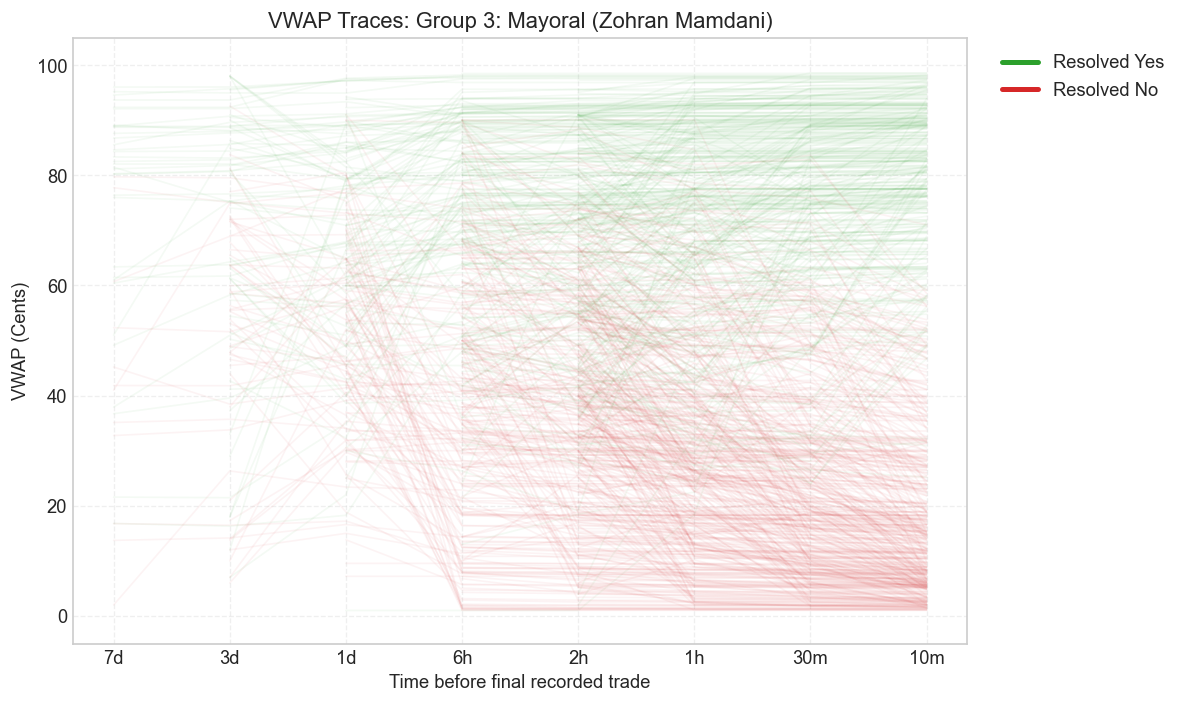

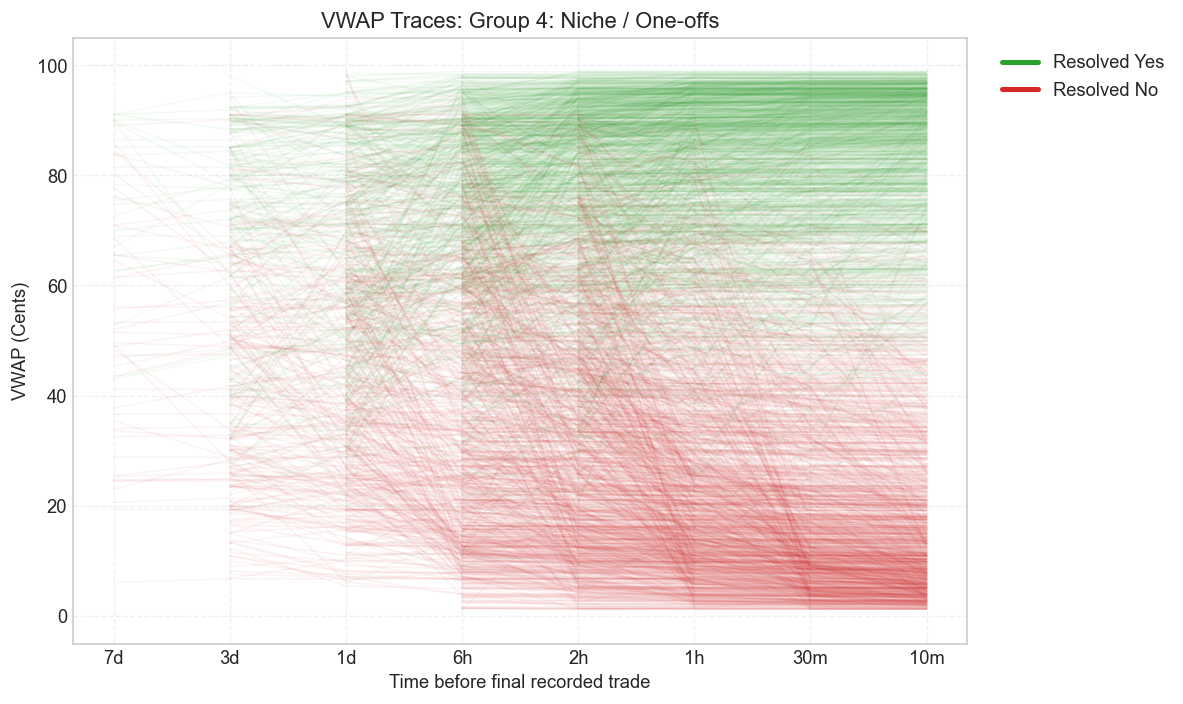

In [11]:
for g in subgroups:
    g_df = df_mention[df_mention["subgroup"] == g].copy()
    if g_df.empty:
        continue
    fig = plot_vwap_traces(g_df, title=f"VWAP Traces: {g}")
    plt.show()

---
## 7. MAD Summary Across Subgroups

Mean Absolute Deviation (MAD) summarizes the absolute gap between observed YES rates and mean implied probabilities within each bucket. The chart is descriptive and its denominators vary by horizon because some contracts lack a given lookback. A lower value at a shorter lookback is not by itself evidence of a monotonic convergence process; compare matched contracts with event-clustered uncertainty.


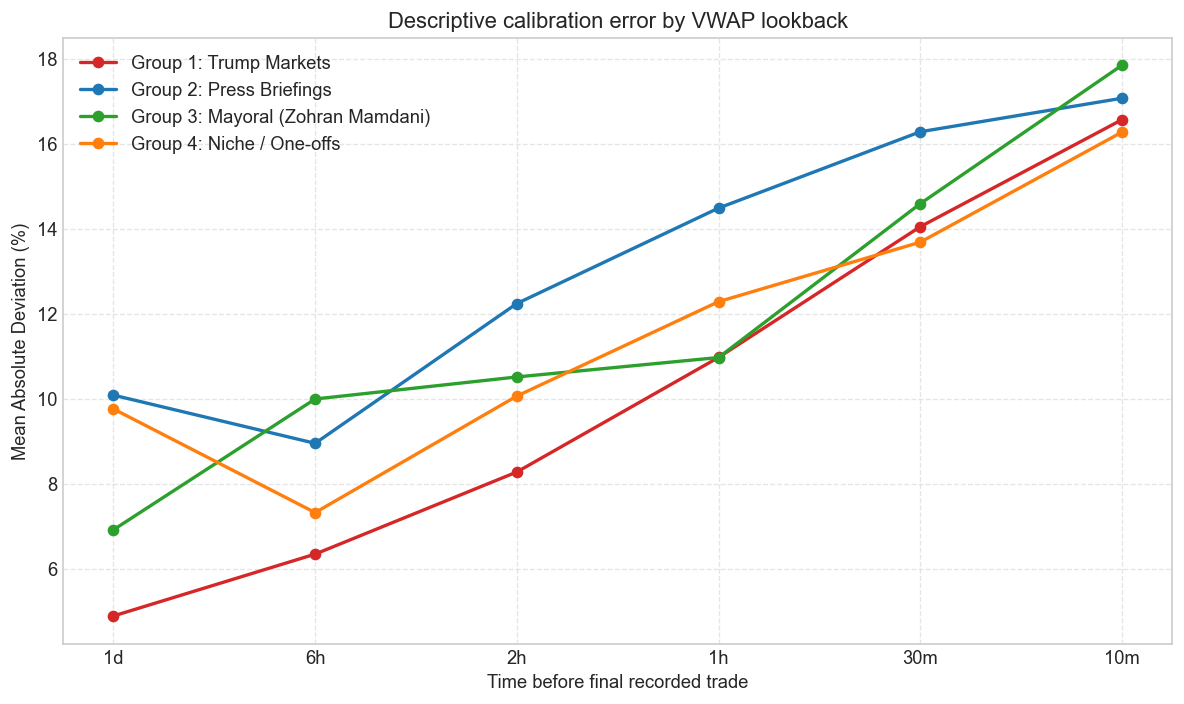

In [12]:
intervals = ["1d", "6h", "2h", "1h", "30m", "10m"]
mad_over_time = {}
subgroup_colors = {
    "Group 1: Trump Markets": "#d62728",
    "Group 2: Press Briefings": "#1f77b4",
    "Group 3: Mayoral (Zohran Mamdani)": "#2ca02c",
    "Group 4: Niche / One-offs": "#ff7f0e",
}

for g in subgroups:
    g_df = df_mention[df_mention["subgroup"] == g]
    _, mads = multi_horizon_calibration(g_df, intervals, bin_size=10)
    mad_over_time[g] = mads

fig = plot_mad_summary(mad_over_time, intervals, colors=subgroup_colors)
plt.show()

---
## 8. Trading Strategy Backtest

We show in-sample threshold diagnostics after Kalshi taker fees. The VWAP is a retrospective benchmark, so this is not a guaranteed execution result. The subgroup heatmaps are exploratory; the pooled table below them uses all eligible contracts so trade counts and PnL are weighted consistently. A trading claim requires chronological, event-level holdout validation with spread, depth, slippage, and queue assumptions.

Two strategies are shown:
- **Buy YES**: buy YES on contracts whose 2h VWAP exceeds the threshold.
- **Buy NO**: buy NO on contracts whose 2h VWAP is below the threshold.


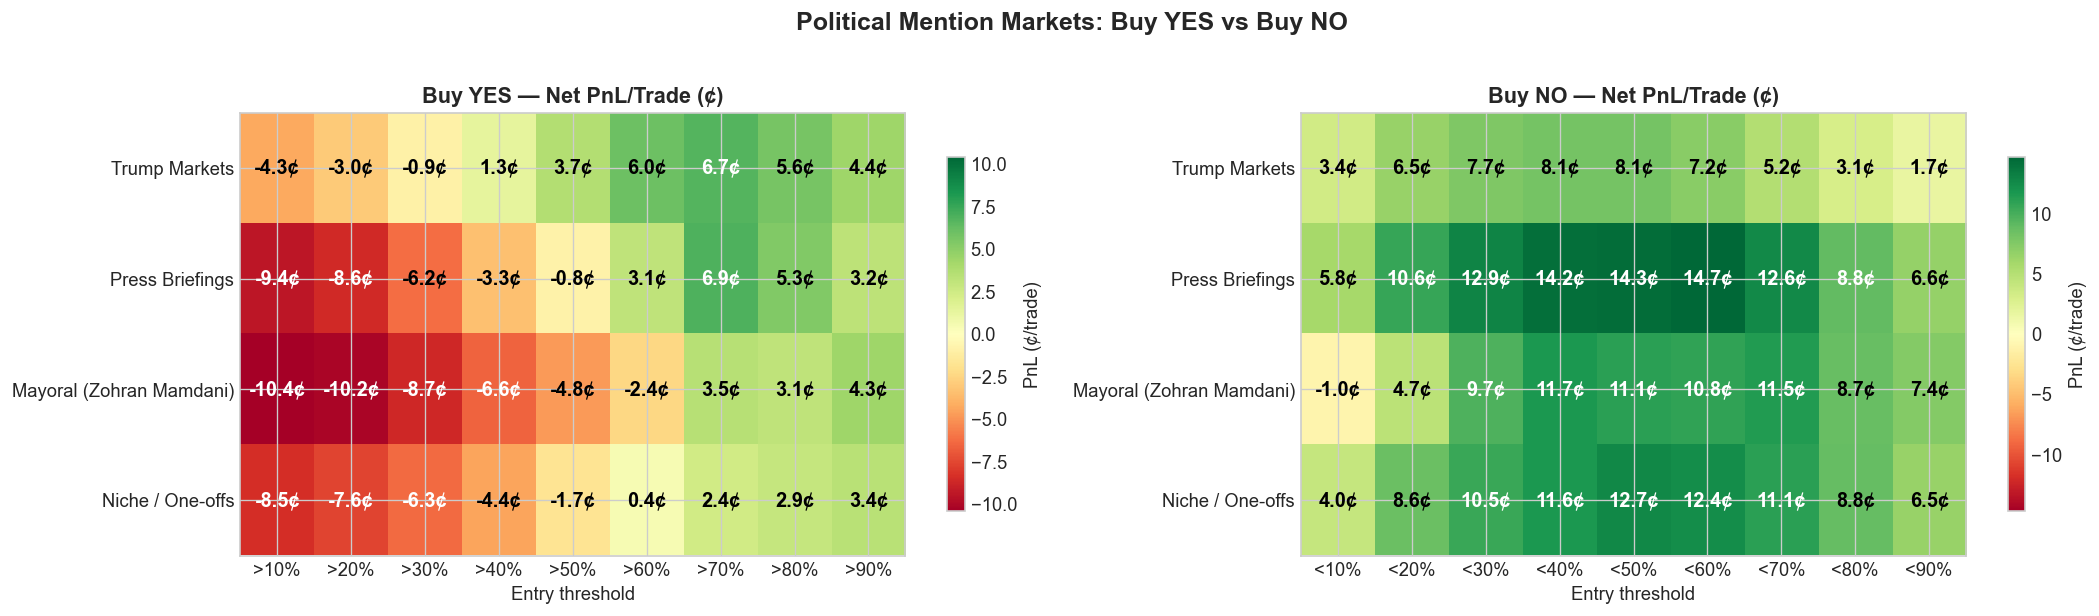


Pooled Buy YES strategy (all eligible political contracts):
  >10%: 9,198 trades, net PnL -6.2¢/trade, hit rate 49.0%
  >20%: 7,944 trades, net PnL -5.1¢/trade, hit rate 56.2%
  >30%: 6,815 trades, net PnL -3.3¢/trade, hit rate 63.8%
  >40%: 5,835 trades, net PnL -1.1¢/trade, hit rate 71.0%
  >50%: 4,969 trades, net PnL +1.3¢/trade, hit rate 77.8%
  >60%: 4,069 trades, net PnL +3.7¢/trade, hit rate 84.5%
  >70%: 3,036 trades, net PnL +5.4¢/trade, hit rate 90.8%
  >80%: 2,006 trades, net PnL +4.6¢/trade, hit rate 94.4%
  >90%: 817 trades, net PnL +4.0¢/trade, hit rate 98.5%

Pooled Buy NO strategy (all eligible political contracts):
  <10%: 1,073 trades, net PnL +3.4¢/trade, hit rate 98.7%
  <20%: 2,326 trades, net PnL +7.1¢/trade, hit rate 97.5%
  <30%: 3,451 trades, net PnL +8.8¢/trade, hit rate 94.9%
  <40%: 4,432 trades, net PnL +9.6¢/trade, hit rate 91.5%
  <50%: 5,298 trades, net PnL +9.8¢/trade, hit rate 87.6%
  <60%: 6,202 trades, net PnL +9.2¢/trade, hit rate 82.5%
  <70%: 7,2

In [13]:
thresholds = [10, 20, 30, 40, 50, 60, 70, 80, 90]
no_thresholds = thresholds.copy()

subgroups = ["Group 1: Trump Markets", "Group 2: Press Briefings",
             "Group 3: Mayoral (Zohran Mamdani)", "Group 4: Niche / One-offs"]

# Subgroup-level heatmaps are useful for exploration.
yes_rows = []
no_rows = []
for g in subgroups:
    g_df = df_mention[df_mention["subgroup"] == g]
    if len(g_df) < 20:
        continue
    for side, out in [("yes", yes_rows), ("no", no_rows)]:
        strat = strategy_profits(g_df, thresholds=thresholds, side=side)
        for _, row in strat.iterrows():
            out.append({"subgroup": g, "threshold": int(row["threshold"]),
                        "trades": int(row["trades"]), "net_pnl": row["net_pnl_per_trade"],
                        "hit_rate": row["hit_rate"], "net_return": row["net_return"]})

yes_df = pd.DataFrame(yes_rows)
no_df = pd.DataFrame(no_rows)

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, strat_df, title, label_fmt in [
    (axes[0], yes_df, "Buy YES", ">{t}%"),
    (axes[1], no_df, "Buy NO", "<{t}%"),
]:
    if strat_df.empty:
        continue
    pivot = strat_df.pivot(index="subgroup", columns="threshold", values="net_pnl")
    data = pivot.values
    vmax = max(abs(data.min()), abs(data.max()), 5)
    im = ax.imshow(data, cmap="RdYlGn", aspect="auto", vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels([f"{label_fmt.format(t=t)}" for t in pivot.columns], fontsize=11)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels([s.replace("Group ", "").split(":")[1].strip() for s in pivot.index], fontsize=11)
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = data[i, j]
            tc = "white" if abs(val) > vmax * 0.6 else "black"
            ax.text(j, i, f"{val:.1f}¢", ha="center", va="center",
                    fontsize=12, fontweight="bold", color=tc)
    ax.set_title(f"{title} — Net PnL/Trade (¢)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Entry threshold")
    fig.colorbar(im, ax=ax, label="PnL (¢/trade)", shrink=0.8)
plt.suptitle("Political Mention Markets: Buy YES vs Buy NO", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Pooled summary: apply the metric once to all eligible contracts rather than
# averaging subgroup means while displaying summed trade counts.
pooled_yes = strategy_profits(df_mention, thresholds=thresholds, side="yes")
pooled_no = strategy_profits(df_mention, thresholds=no_thresholds, side="no")
print("\nPooled Buy YES strategy (all eligible political contracts):")
for _, row in pooled_yes.iterrows():
    print(f"  >{int(row['threshold'])}%: {int(row['trades']):,} trades, "
          f"net PnL {row['net_pnl_per_trade']:+.1f}¢/trade, hit rate {row['hit_rate']:.1%}")
print("\nPooled Buy NO strategy (all eligible political contracts):")
for _, row in pooled_no.iterrows():
    print(f"  <{int(row['threshold'])}%: {int(row['trades']):,} trades, "
          f"net PnL {row['net_pnl_per_trade']:+.1f}¢/trade, hit rate {row['hit_rate']:.1%}")
print("\nThese are in-sample descriptive backtests; use chronological event-level validation before treating them as trading evidence.")


---
## 9. Trump Markets Deep Dive: YES vs NO

Trump markets are the highest-volume political mention series. We compare Buy YES and Buy NO strategies specifically for this subgroup.


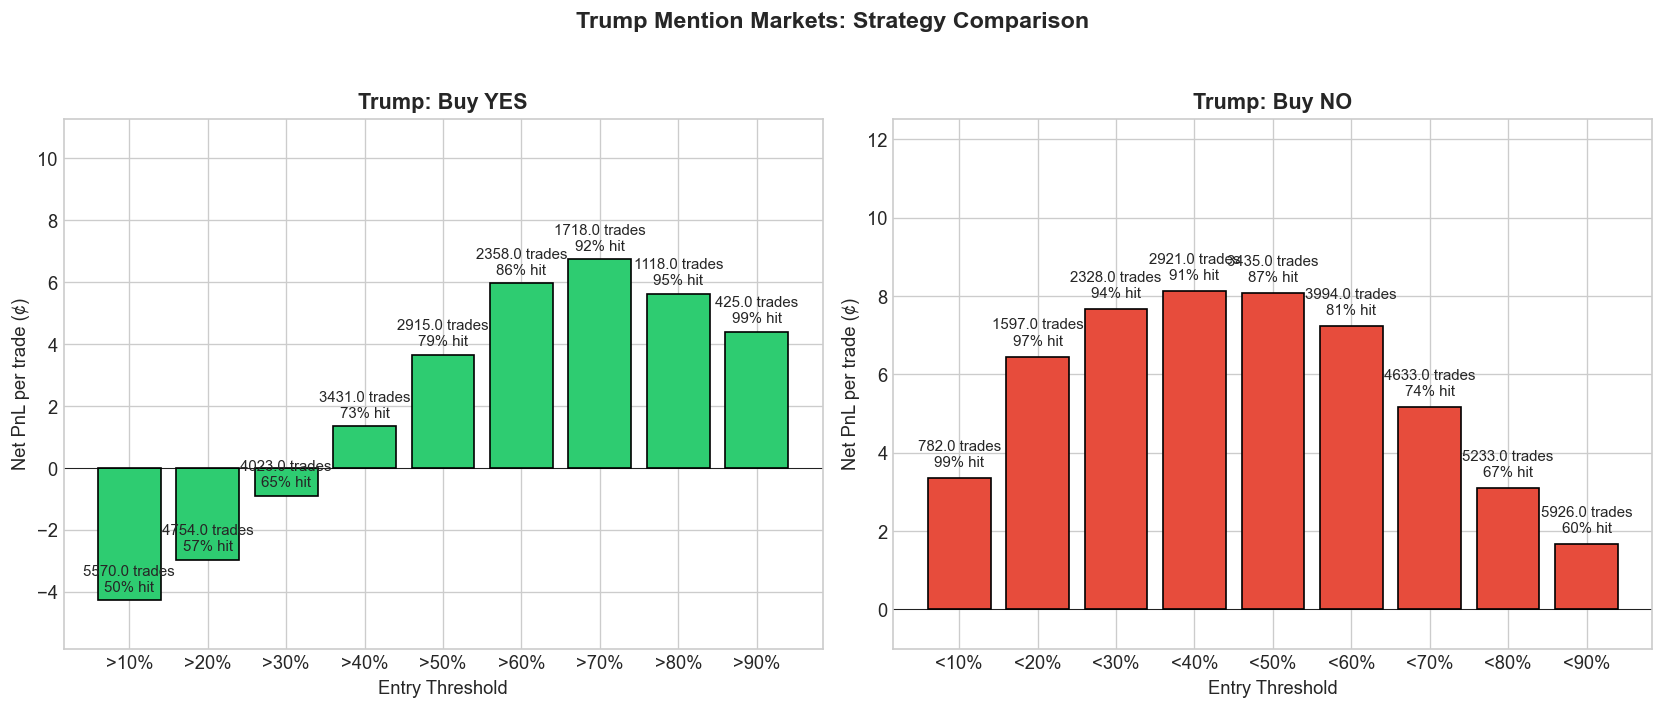

In [14]:
trump_df = df_mention[df_mention["subgroup"] == "Group 1: Trump Markets"].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Buy YES
yes_strat = strategy_profits(trump_df, thresholds=thresholds, side="yes")
axes[0].bar([f">{t}%" for t in thresholds],
            yes_strat["net_pnl_per_trade"].values, color="#2ecc71", edgecolor="black")
axes[0].set_title("Trump: Buy YES", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Entry Threshold", fontsize=11)
axes[0].set_ylabel("Net PnL per trade (\u00a2)")
axes[0].axhline(0, color="black", linewidth=0.5)
for i, row in yes_strat.iterrows():
    axes[0].text(i, row["net_pnl_per_trade"] + 0.3,
                 f'{row["trades"]} trades\n{row["hit_rate"]:.0%} hit',
                 ha="center", fontsize=9)

# Buy NO
no_strat = strategy_profits(trump_df, thresholds=thresholds, side="no")
axes[1].bar([f"<{t}%" for t in thresholds],
            no_strat["net_pnl_per_trade"].values, color="#e74c3c", edgecolor="black")
axes[1].set_title("Trump: Buy NO", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Entry Threshold", fontsize=11)
axes[1].set_ylabel("Net PnL per trade (\u00a2)")
axes[1].axhline(0, color="black", linewidth=0.5)
for i, row in no_strat.iterrows():
    axes[1].text(i, row["net_pnl_per_trade"] + 0.3,
                 f'{row["trades"]} trades\n{row["hit_rate"]:.0%} hit',
                 ha="center", fontsize=9)

# Pad y-axis so annotations don't collide with subplot titles
for ax in axes:
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin - 1, ymax + 4)

plt.suptitle("Trump Mention Markets: Strategy Comparison", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

---
## 10. Conclusions

This notebook is a corrected exploratory view of the broad political snapshot. Its code now categorizes by stable ticker prefix, retains Trump metadata buckets `A` and `B`, plots calibration at within-bucket mean implied probabilities, labels VWAP horizons relative to the final recorded trade, and reports pooled strategy summaries with trade-weighted denominators. The current Trump-specific audit and uncertainty-aware conclusions live in the [consolidated validation notebook](output/mention-markets-validation-consolidated.ipynb) and [issue report](output/mention-markets-validation-report.md).

The Trump result is narrower than the original essay claim. In the refreshed 2-hour audit, contracts priced at 25–35% resolved YES below their mean implied probability, while the 70%+ group was approximately calibrated within the event-cluster confidence interval. The low-price result supports a long-shot-side discrepancy; the high-price “much greater than 70%” claim is not independently established. The original pooled threshold backtests remain exploratory because they use in-sample VWAP thresholds, correlated contracts within events, and assumed VWAP execution.

### Limitations

- Weekly cumulative trade-position snapshots are not independent observations and include both sides of trades.
- Contract-level rows within one speech or event are correlated; uncertainty should be clustered by event.
- VWAP is a descriptive historical price, not a guaranteed executable fill; spread, depth, and queue position are not modeled.
- The final recorded trade anchor is different from settlement time and does not identify time before the speech itself.
- Strategy results require chronological out-of-sample validation before they can support a trading claim.
